# Лабораторная работа №5. Квантовые сумматоры и алгоритм Гровера
**Вариант 21**

### Цель работы
Ознакомление с выполнением простого сложения с помощью квантовых схем, ознакомление с алгоритмом Гровера и его реализацией в квантовых системах.

### Содержание работы
1. **Задание 1.** Полный одноразрядный сумматор: прямой 5-кубитный вариант ($A=1$, $B=0$, $X=1$), вариант из двух полусумматоров и вентиля ИЛИ, исчерпывающее тестирование всех 8 наборов входов; многоразрядный сумматор с последовательным переносом (*ripple-carry adder*) для $n=2,3,4$ и проверка всех $2^n \cdot 2^n$ пар слагаемых.
2. **Задание 2.** Квантовая схема булевой функции варианта 21
   $$F(A,B,C,D) = (A \land B) \oplus (C \lor D)$$
   в двух версиях (базовой и оптимизированной) из модульных подсхем NOT/AND/OR/XOR/NAND/NOR/MAJ с обратным вычислением (*uncomputation*) анцилл.
3. **Задание 3.** Моделирование однокубитного ($p_1 = 0.001$) и двухкубитного ($p_2 \in \{0;\,0.001;\,0.005;\,0.01;\,0.02\}$) деполяризующего шума для обеих версий схемы функции.
4. **Задание 4.** Построение и матричная верификация фазового оракула и диффузора Гровера для $n = 2,3,4,5$; сборка алгоритма Гровера и проверка формулы $P(k) = \sin^2\big((2k+1)\theta\big)$ при $n=3$.
5. **Задание 5.** Поиск алгоритмом Гровера в пространстве $N = 2^7 = 128$ для состояния $|w\rangle = |1010011\rangle$: зависимость $P(k)$, выбор оптимального $k$, устойчивость оценки оптимума при разном числе измерений.
6. **Задание 6.** Алгоритм Гровера при $M$ решениях ($N = 2^6 = 64$): $M \in \{1,2,3,4,8\}$, а также предельные случаи $M = N/2$ и $M = 3N/4$.
7. **Задание 7 (вариант 21).** Поиск состояния $|0101010\rangle$ при $N = 2^7 = 128$; сводная таблица по группе вариантов 21–30; влияние двухкубитного шума на положение и высоту максимума $P(k)$.

### Параметры варианта 21
| Параметр | Значение |
|---|---|
| Функция (задание 2) | $F(A,B,C,D) = (A \land B) \oplus (C \lor D)$ |
| Пространство поиска (задания 5, 7) | $n = 7$, $N = 2^7 = 128$ |
| Отмеченное состояние (задание 7) | $\|w\rangle = \|0101010\rangle$ |
| Группа вариантов | 21–30 при $N = 2^7$ |

In [1]:
# Если пакеты qiskit / qiskit-aer отсутствуют в окружении, раскомментируйте строку ниже:
# !pip install -q qiskit qiskit-aer matplotlib numpy

%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
from math import pi, floor, sqrt, sin, asin

import qiskit
import qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

sim = AerSimulator()
print(f"qiskit {qiskit.__version__}, qiskit-aer {qiskit_aer.__version__}, numpy {np.__version__}")
print("Симулятор AerSimulator инициализирован.")

qiskit 2.6.2, qiskit-aer 0.18.4, numpy 2.5.5
Симулятор AerSimulator инициализирован.


---
## Задание 1. Квантовые сумматоры

### Теория
Полный одноразрядный сумматор принимает три бита — слагаемые $A$, $B$ и входной перенос $X = C_{\text{in}}$ — и вычисляет сумму $S$ и выходной перенос $C = C_{\text{out}}$:
$$S = A \oplus B \oplus X, \qquad C = (A \land B) \oplus (B \land X) \oplus (A \land X).$$
Перенос $C$ — это мажоритарная функция $C = \mathrm{MAJ}(A,B,X)$: она равна 1, когда хотя бы два входа из трёх равны 1. Поэтому перенос реализуется тремя вентилями Тоффоли `CCX`, каждый из которых вычисляет одно парное произведение, а сумма — тремя `CX`.

**Полусумматор** $\mathrm{HA}(a,b)$ даёт $S = a \oplus b$ и $C = a \land b$: перенос — один `CCX`, а сумма — два `CX`, если она записывается в отдельный чистый кубит (при записи «на месте», в кубит одного из слагаемых, достаточно одного `CX`). Полный сумматор можно собрать из двух полусумматоров:
$$\mathrm{HA}_1(A,B) \to (S_1, C_1), \qquad \mathrm{HA}_2(S_1,X) \to (S, C_2), \qquad C = C_1 \lor C_2,$$
где дизъюнкция реализуется по правилу де Моргана $C_1 \lor C_2 = \lnot(\lnot C_1 \land \lnot C_2)$ через инверсии и один `CCX`.

**Многоразрядный сумматор с последовательным переносом** для $n$-битных чисел использует $4n+1$ кубитов: $n$ битов $A$, $n$ битов $B$, $n$ битов суммы $S$ и цепочку переносов $c_0,\dots,c_n$ ($c_0 = 0$). Для каждого разряда $i$:
$$s_i \leftarrow a_i \oplus b_i \oplus c_i, \qquad c_{i+1} = \mathrm{MAJ}(a_i, b_i, c_i),$$
то есть 3 `CX` и 3 `CCX` на разряд.

In [2]:
print("=== ЗАДАНИЕ 1.1: полный сумматор, A=1, B=0, X=1 ===")
print("Кубиты: q0=A, q1=B, q2=X, q3=S, q4=C\n")

qc = QuantumCircuit(5, 2)
qc.x(0)          # A = 1
qc.x(2)          # X = 1
qc.cx(0, 3); qc.cx(1, 3); qc.cx(2, 3)              # S = A ⊕ B ⊕ X
qc.ccx(0, 1, 4); qc.ccx(1, 2, 4); qc.ccx(0, 2, 4)  # C = AB ⊕ BX ⊕ AX

sv = Statevector(qc)
probs = sv.probabilities_dict()
state = max(probs, key=probs.get)
amplitudes = {str(k): complex(np.round(v, 6)) for k, v in sv.to_dict().items()}
print("Вектор состояния (без измерений), порядок битов q4 q3 q2 q1 q0:")
print(f"  |{state}>  = |C S X B A>,  ненулевые амплитуды: {amplitudes}")
print(f"  S = q3 = {state[1]},  C = q4 = {state[0]}")
print("  Проверка: 1 + 0 + 1 = 10₂  ->  S = 0, C = 1 (строка 101 таблицы истинности).\n")

print("Схема полного сумматора (без измерений):")
print(qc.draw('text'))

qcm = QuantumCircuit(5, 2)
qcm.x(0); qcm.x(2)
qcm.cx(0, 3); qcm.cx(1, 3); qcm.cx(2, 3)
qcm.ccx(0, 1, 4); qcm.ccx(1, 2, 4); qcm.ccx(0, 2, 4)
qcm.measure(3, 0)   # S -> c0
qcm.measure(4, 1)   # C -> c1
counts = sim.run(qcm, shots=1024, seed_simulator=11).result().get_counts()
print("\nРаспределение измерений (строка c1 c0 = C S), shots=1024:")
print(" ", counts)
key = list(counts)[0]
print(f"  Единственный исход: C = {key[0]}, S = {key[1]}  ->  сумма 1+0+1 = 10₂.")

=== ЗАДАНИЕ 1.1: полный сумматор, A=1, B=0, X=1 ===
Кубиты: q0=A, q1=B, q2=X, q3=S, q4=C

Вектор состояния (без измерений), порядок битов q4 q3 q2 q1 q0:
  |10101>  = |C S X B A>,  ненулевые амплитуды: {'10101': (1+0j)}
  S = q3 = 0,  C = q4 = 1
  Проверка: 1 + 0 + 1 = 10₂  ->  S = 0, C = 1 (строка 101 таблицы истинности).

Схема полного сумматора (без измерений):
     ┌───┐                              
q_0: ┤ X ├──■──────────────■─────────■──
     └───┘  │              │         │  
q_1: ───────┼────■─────────■────■────┼──
     ┌───┐  │    │         │    │    │  
q_2: ┤ X ├──┼────┼────■────┼────■────■──
     └───┘┌─┴─┐┌─┴─┐┌─┴─┐  │    │    │  
q_3: ─────┤ X ├┤ X ├┤ X ├──┼────┼────┼──
          └───┘└───┘└───┘┌─┴─┐┌─┴─┐┌─┴─┐
q_4: ────────────────────┤ X ├┤ X ├┤ X ├
                         └───┘└───┘└───┘
c: 2/═══════════════════════════════════
                                        

Распределение измерений (строка c1 c0 = C S), shots=1024:
  {'10': 1024}
  Единственный исход: C = 

In [3]:
print("=== ЗАДАНИЕ 1.2: полный сумматор на 5 кубитах, все 8 наборов входов ===")

def full_adder_5q(a, b, x, measure=True):
    """q0=A, q1=B, q2=X, q3=S, q4=C. Только X, CX, CCX; без анцилл и промежуточных измерений."""
    qc = QuantumCircuit(5, 2) if measure else QuantumCircuit(5)
    if a: qc.x(0)
    if b: qc.x(1)
    if x: qc.x(2)
    qc.cx(0, 3); qc.cx(1, 3); qc.cx(2, 3)
    qc.ccx(0, 1, 4); qc.ccx(1, 2, 4); qc.ccx(0, 2, 4)
    if measure:
        qc.measure(3, 0)   # S -> c0
        qc.measure(4, 1)   # C -> c1
    return qc

TRUTH = [(0, 0, 0, 0, 0), (0, 0, 1, 1, 0), (0, 1, 0, 1, 0), (0, 1, 1, 0, 1),
         (1, 0, 0, 1, 0), (1, 0, 1, 0, 1), (1, 1, 0, 0, 1), (1, 1, 1, 1, 1)]

hdr = f"{'A':>2} {'B':>2} {'X':>2} | {'S ожид':>6} {'C ожид':>6} | {'S факт':>6} {'C факт':>6} | статус"
print(hdr)
print("-" * len(hdr))
for a, b, x, s_exp, c_exp in TRUTH:
    counts = sim.run(full_adder_5q(a, b, x), shots=1024, seed_simulator=12).result().get_counts()
    assert len(counts) == 1, f"недетерминированный результат: {counts}"
    key = list(counts)[0]
    c_got, s_got = int(key[0]), int(key[1])
    assert (s_got, c_got) == (s_exp, c_exp), (a, b, x, s_got, c_got)
    print(f"{a:>2} {b:>2} {x:>2} | {s_exp:>6} {c_exp:>6} | {s_got:>6} {c_got:>6} | OK")

gate5 = full_adder_5q(0, 0, 0, measure=False)
ops5 = gate5.count_ops()
print(f"\nМетрики схемы (без измерений): кубитов={gate5.num_qubits}, "
      f"CX={ops5.get('cx', 0)}, CCX={ops5.get('ccx', 0)}, X={ops5.get('x', 0)}, глубина={gate5.depth()}")
print("Все 8 строк таблицы истинности подтверждены assert-проверкой по 1024 shots.")

=== ЗАДАНИЕ 1.2: полный сумматор на 5 кубитах, все 8 наборов входов ===
 A  B  X | S ожид C ожид | S факт C факт | статус
-------------------------------------------------
 0  0  0 |      0      0 |      0      0 | OK
 0  0  1 |      1      0 |      1      0 | OK
 0  1  0 |      1      0 |      1      0 | OK
 0  1  1 |      0      1 |      0      1 | OK
 1  0  0 |      1      0 |      1      0 | OK
 1  0  1 |      0      1 |      0      1 | OK
 1  1  0 |      0      1 |      0      1 | OK
 1  1  1 |      1      1 |      1      1 | OK

Метрики схемы (без измерений): кубитов=5, CX=3, CCX=3, X=0, глубина=5
Все 8 строк таблицы истинности подтверждены assert-проверкой по 1024 shots.


In [4]:
print("=== ЗАДАНИЕ 1.3: полный сумматор из двух полусумматоров и вентиля ИЛИ ===")
print("Кубиты: q0=A, q1=B, q2=X; HA1: q3=S1, q4=C1; HA2: q5=S, q6=C2; q7 = C1 ИЛИ C2\n")

def full_adder_ha(a, b, x, measure=True):
    """Полный сумматор из двух полусумматоров; ИЛИ(C1, C2) реализовано через X/CCX/X."""
    qc = QuantumCircuit(8, 2) if measure else QuantumCircuit(8)
    if a: qc.x(0)
    if b: qc.x(1)
    if x: qc.x(2)
    qc.cx(0, 3); qc.cx(1, 3); qc.ccx(0, 1, 4)   # HA1(A, B): S1 = A⊕B, C1 = A∧B
    qc.cx(3, 5); qc.cx(2, 5); qc.ccx(3, 2, 6)   # HA2(S1, X): S = S1⊕X, C2 = S1∧X
    qc.x(4); qc.x(6)                      # C1∨C2 = ¬(¬C1 ∧ ¬C2)
    qc.ccx(4, 6, 7); qc.x(7)
    qc.x(4); qc.x(6)                      # восстановление C1 и C2
    if measure:
        qc.measure(5, 0)   # S -> c0
        qc.measure(7, 1)   # C -> c1
    return qc

hdr = f"{'A':>2} {'B':>2} {'X':>2} | {'S ожид':>6} {'C ожид':>6} | {'S факт':>6} {'C факт':>6} | статус"
print(hdr)
print("-" * len(hdr))
for a, b, x, s_exp, c_exp in TRUTH:
    counts = sim.run(full_adder_ha(a, b, x), shots=1024, seed_simulator=13).result().get_counts()
    assert len(counts) == 1, f"недетерминированный результат: {counts}"
    key = list(counts)[0]
    c_got, s_got = int(key[0]), int(key[1])
    assert (s_got, c_got) == (s_exp, c_exp), (a, b, x, s_got, c_got)
    print(f"{a:>2} {b:>2} {x:>2} | {s_exp:>6} {c_exp:>6} | {s_got:>6} {c_got:>6} | OK")

gate8 = full_adder_ha(0, 0, 0, measure=False)
ops8 = gate8.count_ops()
print(f"\nМетрики схемы (без измерений): кубитов={gate8.num_qubits}, "
      f"CX={ops8.get('cx', 0)}, CCX={ops8.get('ccx', 0)}, X={ops8.get('x', 0)}, глубина={gate8.depth()}")

print("\nСравнение реализаций полного сумматора:")
hdr2 = f"{'реализация':<32} {'кубитов':>7} {'CX':>4} {'CCX':>4} {'X':>4} {'глубина':>7}"
print(hdr2)
print("-" * len(hdr2))
for name, g, o in [("прямая 5-кубитная", gate5, ops5), ("из двух полусумматоров", gate8, ops8)]:
    print(f"{name:<32} {g.num_qubits:>7} {o.get('cx', 0):>4} {o.get('ccx', 0):>4} {o.get('x', 0):>4} {g.depth():>7}")

=== ЗАДАНИЕ 1.3: полный сумматор из двух полусумматоров и вентиля ИЛИ ===
Кубиты: q0=A, q1=B, q2=X; HA1: q3=S1, q4=C1; HA2: q5=S, q6=C2; q7 = C1 ИЛИ C2

 A  B  X | S ожид C ожид | S факт C факт | статус
-------------------------------------------------
 0  0  0 |      0      0 |      0      0 | OK
 0  0  1 |      1      0 |      1      0 | OK
 0  1  0 |      1      0 |      1      0 | OK
 0  1  1 |      0      1 |      0      1 | OK
 1  0  0 |      1      0 |      1      0 | OK
 1  0  1 |      0      1 |      0      1 | OK
 1  1  0 |      0      1 |      0      1 | OK
 1  1  1 |      1      1 |      1      1 | OK

Метрики схемы (без измерений): кубитов=8, CX=4, CCX=3, X=5, глубина=8

Сравнение реализаций полного сумматора:
реализация                       кубитов   CX  CCX    X глубина
---------------------------------------------------------------
прямая 5-кубитная                      5    3    3    0       5
из двух полусумматоров                 8    4    3    5       8


=== ЗАДАНИЕ 1.4: сумматор с последовательным переносом (ripple-carry) ===
 n  кубитов   CX  CCX  глубина  пар проверено   статус
------------------------------------------------------
 2        9    6    6        8             16       OK
 3       13    9    9       11             64       OK


 4       17   12   12       14            256       OK

Все пары (a, b) для n = 2 (16), n = 3 (64) и n = 4 (256) сложены верно (проверка assert по измеренному (n+1)-битному результату).


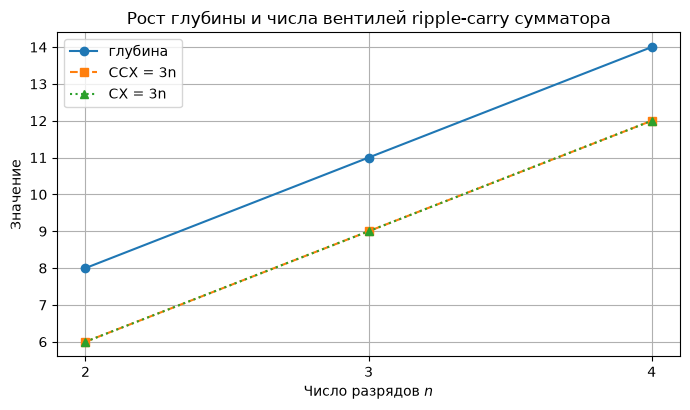

In [5]:
print("=== ЗАДАНИЕ 1.4: сумматор с последовательным переносом (ripple-carry) ===")

def ripple_adder(n):
    """4n+1 кубитов: A(q0..), B(qn..), S(q2n..), переносы c0..cn(q3n..q4n)."""
    qc = QuantumCircuit(4 * n + 1)
    for i in range(n):
        ai, bi, si, ci = i, n + i, 2 * n + i, 3 * n + i
        qc.cx(ai, si); qc.cx(bi, si); qc.cx(ci, si)
        qc.ccx(ai, bi, ci + 1); qc.ccx(bi, ci, ci + 1); qc.ccx(ai, ci, ci + 1)
    return qc

def ripple_test(n, shots=64):
    """Исчерпывающая проверка всех 2^n * 2^n пар (a, b) сравнением с a+b."""
    gates = ripple_adder(n)
    meas_q = list(range(2 * n, 3 * n)) + [4 * n]   # s0..s_{n-1}, c_n
    meas_c = list(range(n + 1))
    tested = 0
    for a in range(2 ** n):
        for b in range(2 ** n):
            qc = QuantumCircuit(4 * n + 1, n + 1)
            for i in range(n):
                if (a >> i) & 1: qc.x(i)
                if (b >> i) & 1: qc.x(n + i)
            qc.compose(gates, inplace=True)
            qc.measure(meas_q, meas_c)
            counts = sim.run(qc, shots=shots, seed_simulator=n * 1000 + a * 64 + b).result().get_counts()
            assert len(counts) == 1, f"n={n}, {a}+{b}: недетерминированный результат {counts}"
            got = int(list(counts)[0], 2)
            assert got == a + b, f"n={n}: {a} + {b} = {a + b}, получено {got}"
            tested += 1
    return tested

hdr = f"{'n':>2} {'кубитов':>8} {'CX':>4} {'CCX':>4} {'глубина':>8} {'пар проверено':>14} {'статус':>8}"
print(hdr)
print("-" * len(hdr))
rows = []
for n in (2, 3, 4):
    g = ripple_adder(n)
    tested = ripple_test(n)
    o = g.count_ops()
    rows.append((n, g.num_qubits, o.get('cx', 0), o.get('ccx', 0), g.depth(), tested))
    print(f"{n:>2} {g.num_qubits:>8} {o.get('cx', 0):>4} {o.get('ccx', 0):>4} {g.depth():>8} {tested:>14} "
          f"{'OK' if tested == 4 ** n else 'FAIL':>8}")

print("\nВсе пары (a, b) для n = 2 (16), n = 3 (64) и n = 4 (256) сложены верно "
      "(проверка assert по измеренному (n+1)-битному результату).")

plt.figure(figsize=(7, 4.2))
plt.plot([r[0] for r in rows], [r[4] for r in rows], 'o-', label='глубина')
plt.plot([r[0] for r in rows], [r[3] for r in rows], 's--', label='CCX = 3n')
plt.plot([r[0] for r in rows], [r[2] for r in rows], '^:', label='CX = 3n')
plt.xlabel('Число разрядов $n$')
plt.ylabel('Значение')
plt.title('Рост глубины и числа вентилей ripple-carry сумматора')
plt.xticks([2, 3, 4])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Ответы на вопросы задания 1
1. **Почему перенос $C$ нельзя вычислить одним `CCX`?** Перенос равен $C = \mathrm{MAJ}(A,B,X) = (A \land B) \oplus (B \land X) \oplus (A \land X)$ — это не одно произведение, а сумма трёх парных произведений (в схеме — три `CCX` с общей целью $q_4$). Один `CCX` даёт только $A \land B$ и теряет случаи $A=0,\,B=1,\,X=1$ и $A=1,\,B=0,\,X=1$, то есть строки 011 и 101 таблицы истинности.
2. **`CX` и теорема о запрете клонирования.** `CX` переводит $|x\rangle|0\rangle \to |x\rangle|x\rangle$ только для базисных состояний. Для суперпозиции $\alpha|0\rangle+\beta|1\rangle$ получается запутанное состояние $\alpha|00\rangle+\beta|11\rangle$, в котором второй кубит не имеет собственного чистого состояния; копии $(\alpha|0\rangle+\beta|1\rangle)^{\otimes 2}$ не возникает. Это прямое проявление теоремы о запрете клонирования: линейность квантовой механики запрещает унитарное $U$ с $U(|\psi\rangle|0\rangle) = |\psi\rangle|\psi\rangle$ для произвольного неизвестного $|\psi\rangle$.
3. **Как уменьшить глубину сумматора и какой ценой?** Глубину $O(n)$ можно уменьшить до $O(\log n)$ схемой с ускоренным переносом (*carry-lookahead*, параллельный префикс): сигналы generate $g_i = a_i \land b_i$ и propagate $p_i = a_i \oplus b_i$ объединяются древовидной схемой, что требует дополнительных анцилл и большего числа вентилей `CX`/`CCX` (площадь растёт до $O(n\log n)$). Альтернативы — декомпозиции многоуправляемых вентилей с анциллами (меньше глубина, но нужны чистые дополнительные кубиты) и in-place сумматоры (экономия кубитов за счёт роста глубины).

**Вывод по Заданию 1:**
- Прямой 5-кубитный сумматор при $A=1$, $B=0$, $X=1$ даёт вектор состояния $|10101\rangle$ в порядке $q_4q_3q_2q_1q_0$, то есть $S=0$, $C=1$ — строка $1+0+1=10_2$ таблицы истинности; измерение 1024 shots даёт единственный исход `10`.
- Обе реализации прошли все 8 наборов входов: 5-кубитная схема имеет 5 кубитов, 3 `CX`, 3 `CCX`, глубину 5; схема из двух полусумматоров — 8 кубитов, 4 `CX`, 3 `CCX`, 5 инверсий `X` и глубину 8. Прямая реализация экономичнее по всем метрикам: у неё меньше кубитов, вентилей и глубина.
- Ripple-carry сумматор масштабируется линейно: $4n+1$ кубитов, $3n$ `CX`, $3n$ `CCX`, глубина $3n+2$ (8, 11 и 14 для $n=2,3,4$). Исчерпывающая проверка 16, 64 и 256 пар слагаемых подтвердила правильность сложения.

---
## Задание 2. Булева функция варианта 21

Функция варианта 21:
$$F(A,B,C,D) = (A \land B) \oplus (C \lor D).$$

Схема строится только из модульных подсхем, каждая из которых добавляет вентили в переданную схему и не изменяет входные кубиты. Вспомогательные кубиты вычисляют промежуточные значения, результат копируется на выходной кубит $q_4$ парой `CX`, после чего блок вычислений отменяется применением `inverse()`, так что все анциллы возвращаются в $|0\rangle$:
$$|A,B,C,D\rangle|0\rangle^{\otimes m}|0\rangle_F \;\longrightarrow\; |A,B,C,D\rangle|0\rangle^{\otimes m}|F(A,B,C,D)\rangle.$$

**Базовая версия (9 кубитов):** каждое промежуточное значение получает свой кубит — $q_5 = A \land B$, $q_6 = C \oplus D$, $q_7 = C \land D$, $q_8 = q_6 \oplus q_7 = C \lor D$; затем $q_4 \leftarrow q_4 \oplus q_5$, $q_4 \leftarrow q_4 \oplus q_8$ и `compute.inverse()`.

**Оптимизированная версия (7 кубитов):** $q_5 = A \land B$, $q_6 = C \lor D$ (подсхема OR сразу, без промежуточного $C \oplus D$ и $C \land D$), затем $q_4 \leftarrow q_4 \oplus q_5$, $q_4 \leftarrow q_4 \oplus q_6$ и `compute.inverse()`. Экономия — 2 кубита и 4 вентиля `CX` при том же числе `CCX`.

In [6]:
print("=== ЗАДАНИЕ 2: модульные квантовые подсхемы (вариант 21) ===")
print("F(A,B,C,D) = (A AND B) XOR (C OR D)\n")

def gate_not(qc, a, out):
    """out = NOT a (out должен быть |0>)."""
    qc.x(out); qc.cx(a, out)

def gate_and(qc, a, b, out):
    """out ^= a AND b."""
    qc.ccx(a, b, out)

def gate_or(qc, a, b, out):
    """out ^= a OR b  (a⊕b⊕ab, 2 CX + 1 CCX)."""
    qc.cx(a, out); qc.cx(b, out); qc.ccx(a, b, out)

def gate_xor(qc, a, b, out):
    """out ^= a XOR b."""
    qc.cx(a, out); qc.cx(b, out)

def gate_nand(qc, a, b, out):
    """out = NOT(a AND b) (out должен быть |0>)."""
    qc.ccx(a, b, out); qc.x(out)

def gate_nor(qc, a, b, out):
    """out = NOT(a OR b) (out должен быть |0>)."""
    gate_or(qc, a, b, out); qc.x(out)

def gate_maj(qc, a, b, c, out):
    """out ^= MAJ(a,b,c) = ab ⊕ bc ⊕ ac."""
    qc.ccx(a, b, out); qc.ccx(b, c, out); qc.ccx(a, c, out)

def F_classical(A, B, C, D):
    """Классическая реализация функции варианта 21 на чистом Python."""
    return (A & B) ^ (C | D)

def self_test(name, gate_fn, n_in, ref):
    """Проверка подсхемы на всех 2^n_in наборах входов (Statevector, без выборки)."""
    ok = 0
    for bits in range(2 ** n_in):
        qc = QuantumCircuit(n_in + 1)
        for i in range(n_in):
            if (bits >> i) & 1:
                qc.x(i)
        gate_fn(qc, *range(n_in), n_in)
        probs = Statevector(qc).probabilities_dict()
        key = max(probs, key=probs.get)
        vals = [(bits >> i) & 1 for i in range(n_in)]
        if int(key[0]) == ref(vals) and key[1:] == format(bits, f'0{n_in}b'):
            ok += 1
    print(f"  {name:<6} входов={2 ** n_in:>2}  корректно={ok:>2}  статус={'OK' if ok == 2 ** n_in else 'FAIL'}")

print("Самопроверка подсхем на всех наборах входов:")
self_test("NOT",  gate_not, 1, lambda v: 1 - v[0])
self_test("AND",  gate_and, 2, lambda v: v[0] & v[1])
self_test("OR",   gate_or,  2, lambda v: v[0] | v[1])
self_test("XOR",  gate_xor, 2, lambda v: v[0] ^ v[1])
self_test("NAND", gate_nand, 2, lambda v: 1 - (v[0] & v[1]))
self_test("NOR",  gate_nor, 2, lambda v: 1 - (v[0] | v[1]))
self_test("MAJ",  gate_maj, 3, lambda v: int(sum(v) >= 2))

=== ЗАДАНИЕ 2: модульные квантовые подсхемы (вариант 21) ===
F(A,B,C,D) = (A AND B) XOR (C OR D)

Самопроверка подсхем на всех наборах входов:
  NOT    входов= 2  корректно= 2  статус=OK
  AND    входов= 4  корректно= 4  статус=OK
  OR     входов= 4  корректно= 4  статус=OK
  XOR    входов= 4  корректно= 4  статус=OK
  NAND   входов= 4  корректно= 4  статус=OK
  NOR    входов= 4  корректно= 4  статус=OK
  MAJ    входов= 8  корректно= 8  статус=OK


In [7]:
print("=== ЗАДАНИЕ 2.1: базовая схема (9 кубитов) ===")

def F_basic_compute():
    """Блок вычисления: q5=A∧B, q6=C⊕D, q7=C∧D, q8=C∨D."""
    qc = QuantumCircuit(9)
    gate_and(qc, 0, 1, 5)      # q5 = A ∧ B
    gate_xor(qc, 2, 3, 6)      # q6 = C ⊕ D
    gate_and(qc, 2, 3, 7)      # q7 = C ∧ D
    gate_xor(qc, 6, 7, 8)      # q8 = q6 ⊕ q7 = C ∨ D
    return qc

def F_basic_body():
    """Вся схема: вычисление, копирование на q4, inverse() блока вычисления."""
    comp = F_basic_compute()
    qc = QuantumCircuit(9)
    qc.compose(comp, inplace=True)
    qc.cx(5, 4)     # q4 ^= A ∧ B
    qc.cx(8, 4)     # q4 ^= C ∨ D
    qc.compose(comp.inverse(), inplace=True)
    return qc

def test_boolean(name, body, ancillas, shots=1024, seed=2):
    """Проверка на всех 16 входах: F и состояние анцилл."""
    nq = body.num_qubits
    hdr = f"{'A':>2} {'B':>2} {'C':>2} {'D':>2} | {'F кл':>4} | {'F кв':>4} | {'анциллы':>8} | статус"
    print(hdr)
    print("-" * len(hdr))
    ok = 0
    for bits in range(16):
        A, B, C, D = (bits >> 3) & 1, (bits >> 2) & 1, (bits >> 1) & 1, bits & 1
        qc = QuantumCircuit(nq, 1 + len(ancillas))
        for i, v in enumerate((A, B, C, D)):
            if v: qc.x(i)
        qc.compose(body, inplace=True)
        qc.measure(4, 0)
        qc.measure(ancillas, list(range(1, 1 + len(ancillas))))
        counts = sim.run(qc, shots=shots, seed_simulator=seed * 100 + bits).result().get_counts()
        assert len(counts) == 1, f"недетерминированный результат: {counts}"
        key = list(counts)[0]
        f_q, anc = int(key[-1]), key[:-1]
        f_cl = F_classical(A, B, C, D)
        good = (f_q == f_cl) and ('1' not in anc)
        assert good, (bits, key)
        ok += good
        print(f"{A:>2} {B:>2} {C:>2} {D:>2} | {f_cl:>4} | {f_q:>4} | {anc:>8} | {'OK' if good else 'FAIL'}")
    print(f"Итого: {ok}/16 наборов — ответ совпал с классическим, все анциллы в |0>.\n")

basic_body = F_basic_body()
test_boolean("базовая", basic_body, [5, 6, 7, 8])
o = basic_body.count_ops()
print(f"Метрики базовой схемы: кубитов={basic_body.num_qubits}, CX={o.get('cx', 0)}, "
      f"CCX={o.get('ccx', 0)}, глубина={basic_body.depth()}, анцилл=4")

=== ЗАДАНИЕ 2.1: базовая схема (9 кубитов) ===
 A  B  C  D | F кл | F кв |  анциллы | статус
---------------------------------------------
 0  0  0  0 |    0 |    0 |     0000 | OK
 0  0  0  1 |    1 |    1 |     0000 | OK
 0  0  1  0 |    1 |    1 |     0000 | OK
 0  0  1  1 |    1 |    1 |     0000 | OK
 0  1  0  0 |    0 |    0 |     0000 | OK
 0  1  0  1 |    1 |    1 |     0000 | OK
 0  1  1  0 |    1 |    1 |     0000 | OK
 0  1  1  1 |    1 |    1 |     0000 | OK
 1  0  0  0 |    0 |    0 |     0000 | OK
 1  0  0  1 |    1 |    1 |     0000 | OK
 1  0  1  0 |    1 |    1 |     0000 | OK
 1  0  1  1 |    1 |    1 |     0000 | OK
 1  1  0  0 |    1 |    1 |     0000 | OK
 1  1  0  1 |    0 |    0 |     0000 | OK
 1  1  1  0 |    0 |    0 |     0000 | OK
 1  1  1  1 |    0 |    0 |     0000 | OK
Итого: 16/16 наборов — ответ совпал с классическим, все анциллы в |0>.

Метрики базовой схемы: кубитов=9, CX=10, CCX=4, глубина=9, анцилл=4


In [8]:
print("=== ЗАДАНИЕ 2.2: оптимизированная схема (7 кубитов) ===")

def F_opt_compute():
    """Блок вычисления: q5=A∧B, q6=C∨D — две анциллы вместо четырёх."""
    qc = QuantumCircuit(7)
    gate_and(qc, 0, 1, 5)   # q5 = A ∧ B
    gate_or(qc, 2, 3, 6)    # q6 = C ∨ D
    return qc

def F_opt_body():
    comp = F_opt_compute()
    qc = QuantumCircuit(7)
    qc.compose(comp, inplace=True)
    qc.cx(5, 4)     # q4 ^= A ∧ B
    qc.cx(6, 4)     # q4 ^= C ∨ D
    qc.compose(comp.inverse(), inplace=True)
    return qc

opt_body = F_opt_body()
test_boolean("оптим.", opt_body, [5, 6])
o = opt_body.count_ops()
print(f"Метрики оптимизированной схемы: кубитов={opt_body.num_qubits}, CX={o.get('cx', 0)}, "
      f"CCX={o.get('ccx', 0)}, глубина={opt_body.depth()}, анцилл=2")

print("\nСравнение версий схемы функции F(A,B,C,D) = (A∧B) ⊕ (C∨D):")
hdr = f"{'версия':<18} {'кубитов':>7} {'CX':>4} {'CCX':>4} {'глубина':>7} {'анцилл':>6}"
print(hdr)
print("-" * len(hdr))
for name, body, n_anc in [("базовая", basic_body, 4), ("оптимизированная", opt_body, 2)]:
    oo = body.count_ops()
    print(f"{name:<18} {body.num_qubits:>7} {oo.get('cx', 0):>4} {oo.get('ccx', 0):>4} "
          f"{body.depth():>7} {n_anc:>6}")

=== ЗАДАНИЕ 2.2: оптимизированная схема (7 кубитов) ===
 A  B  C  D | F кл | F кв |  анциллы | статус
---------------------------------------------
 0  0  0  0 |    0 |    0 |       00 | OK
 0  0  0  1 |    1 |    1 |       00 | OK
 0  0  1  0 |    1 |    1 |       00 | OK
 0  0  1  1 |    1 |    1 |       00 | OK
 0  1  0  0 |    0 |    0 |       00 | OK
 0  1  0  1 |    1 |    1 |       00 | OK
 0  1  1  0 |    1 |    1 |       00 | OK
 0  1  1  1 |    1 |    1 |       00 | OK
 1  0  0  0 |    0 |    0 |       00 | OK
 1  0  0  1 |    1 |    1 |       00 | OK
 1  0  1  0 |    1 |    1 |       00 | OK
 1  0  1  1 |    1 |    1 |       00 | OK
 1  1  0  0 |    1 |    1 |       00 | OK
 1  1  0  1 |    0 |    0 |       00 | OK


 1  1  1  0 |    0 |    0 |       00 | OK
 1  1  1  1 |    0 |    0 |       00 | OK
Итого: 16/16 наборов — ответ совпал с классическим, все анциллы в |0>.

Метрики оптимизированной схемы: кубитов=7, CX=6, CCX=4, глубина=7, анцилл=2

Сравнение версий схемы функции F(A,B,C,D) = (A∧B) ⊕ (C∨D):
версия             кубитов   CX  CCX глубина анцилл
---------------------------------------------------
базовая                  9   10    4       9      4
оптимизированная         7    6    4       7      2


**Почему минимум по числу кубитов и минимум по глубине могут не совпадать.** Ширина схемы и её глубина — разные ресурсы. Если анциллы переиспользуются, независимые операции приходится выстраивать в последовательную цепочку: например, при последовательном вычислении $C\oplus D$, затем $C\land D$ и затем $C\lor D$ на одних и тех же кубитах глубина растёт, хотя кубитов требуется меньше. Наоборот, дополнительные чистые анциллы позволяют распараллелить независимые вычисления и уменьшить глубину, но увеличивают ширину схемы. Классический пример — декомпозиция многоуправляемого `MCX`: вариант без анцилл имеет глубину $O(n)$, а с анциллами — $O(\log n)$ (ценой дополнительных кубитов). Поэтому «минимум по кубитам» и «минимум по глубине» — разные критерии, и выбор зависит от того, какой ресурс дефицитен (ширина или время/накопление ошибок).

В нашем случае оптимизированная версия выигрывает по обоим критериям одновременно: замена последовательной цепочки $C\oplus D \to C\land D \to C\lor D$ одной подсхемой OR сокращает и число анцилл (4 → 2), и глубину (9 → 7). Это следствие того, что базовая версия строилась по принципу «каждый промежуточный результат — в отдельный кубит», а не проявления общего закона «меньше кубитов — меньше глубина».

**Вывод по Заданию 2:**
- Все модульные подсхемы (NOT, AND, OR, XOR, NAND, NOR, MAJ) прошли самопроверку на всех своих наборах входов.
- Обе версии схемы дают правильный ответ на всех 16 наборах входов, причём во всех исходах измерений анциллы равны нулю — обратное вычисление `inverse()` работает.
- Базовая версия: 9 кубитов, 10 `CX`, 4 `CCX`, глубина 9, 4 анциллы. Оптимизированная версия: 7 кубитов, 6 `CX`, 4 `CCX`, глубина 7, 2 анциллы. Оптимизация сэкономила 2 кубита, 4 вентиля `CX` и 2 слоя глубины при том же числе `CCX`.

---
## Задание 3. Моделирование деполяризующего шума

Обе версии схемы функции из задания 2 транспилируются в аппаратный базис `['rz', 'sx', 'x', 'cx']` (`optimization_level=1`), после чего на них действует шумовая модель:
- однокубитный деполяризующий шум с вероятностью $p_1 = 0.001$ на вентилях `rz`, `sx`, `x`;
- двухкубитный деполяризующий шум с вероятностью $p_2 \in \{0;\ 0.001;\ 0.005;\ 0.01;\ 0.02\}$ на вентилях `cx`.

Транспиляция обязательна: каждый `CCX` раскладывается примерно в 6 `CX`, и именно эти двухкубитные вентили накапливают основной шум. Для каждого $p_2$ и каждого из 16 входов выполняется 1024 shots; метрика — доля shots с правильным значением выходного бита, усреднённая по входам.

=== ЗАДАНИЕ 3: деполяризующий шум ===
базовая           : после транспиляции CX=34, глубина=31
оптимизированная  : после транспиляции CX=30, глубина=31



Доля правильных ответов (усреднение по 16 входам, 1024 shots):
    p2 |    базовая | оптимизированная
--------------------------------------
   0.0 |     0.9905 |           0.9905
 0.001 |     0.9848 |           0.9846
 0.005 |     0.9617 |           0.9650
  0.01 |     0.9305 |           0.9395
  0.02 |     0.8735 |           0.8921


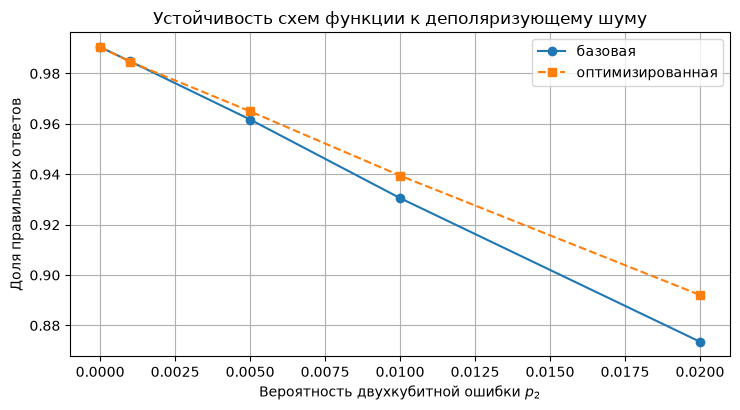


Оценка экспоненциального закона P ≈ exp(-κ · N_CX · p2):
  отношение числа CX: N_баз / N_опт = 1.1333
      p2 |  ln P баз |  ln P опт |  отношение
  --------------------------------------------
   0.001 |   -0.0153 |   -0.0155 |     0.9880
   0.005 |   -0.0390 |   -0.0357 |     1.0942
    0.01 |   -0.0720 |   -0.0625 |     1.1526
    0.02 |   -0.1352 |   -0.1142 |     1.1841
  среднее отношение логарифмов = 1.1047 (ожидается ≈ 1.1333)


In [9]:
print("=== ЗАДАНИЕ 3: деполяризующий шум ===")

P2_VALUES = [0.0, 0.001, 0.005, 0.01, 0.02]

def build_noise_model(p2):
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ['rz', 'sx', 'x'])
    if p2 > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ['cx'])
    return nm

BODIES = {"базовая": basic_body, "оптимизированная": opt_body}
TRANSPILED = {}
for name, body in BODIES.items():
    tqc = transpile(body, basis_gates=['rz', 'sx', 'x', 'cx'], optimization_level=1)
    TRANSPILED[name] = tqc
    print(f"{name:<18}: после транспиляции CX={tqc.count_ops().get('cx', 0)}, глубина={tqc.depth()}")

def fraction_correct(tqc, p2, shots=1024, seed=3):
    nm = build_noise_model(p2)
    total = 0.0
    for bits in range(16):
        A, B, C, D = (bits >> 3) & 1, (bits >> 2) & 1, (bits >> 1) & 1, bits & 1
        qc = QuantumCircuit(tqc.num_qubits, 1)
        for i, v in enumerate((A, B, C, D)):
            if v: qc.x(i)
        qc.compose(tqc, inplace=True)
        qc.measure(4, 0)
        counts = sim.run(qc, shots=shots, noise_model=nm,
                         seed_simulator=seed * 100 + bits).result().get_counts()
        total += counts.get(str(F_classical(A, B, C, D)), 0) / shots
    return total / 16

results = {name: [] for name in BODIES}
for p2 in P2_VALUES:
    for name in BODIES:
        results[name].append(fraction_correct(TRANSPILED[name], p2))

hdr = f"{'p2':>6} | {'базовая':>10} | {'оптимизированная':>16}"
print("\nДоля правильных ответов (усреднение по 16 входам, 1024 shots):")
print(hdr)
print("-" * len(hdr))
for i, p2 in enumerate(P2_VALUES):
    print(f"{p2:>6} | {results['базовая'][i]:>10.4f} | {results['оптимизированная'][i]:>16.4f}")

plt.figure(figsize=(7.5, 4.2))
for name, style in [("базовая", 'o-'), ("оптимизированная", 's--')]:
    plt.plot(P2_VALUES, results[name], style, label=name)
plt.xlabel('Вероятность двухкубитной ошибки $p_2$')
plt.ylabel('Доля правильных ответов')
plt.title('Устойчивость схем функции к деполяризующему шуму')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("\nОценка экспоненциального закона P ≈ exp(-κ · N_CX · p2):")
ratio_cx = TRANSPILED['базовая'].count_ops().get('cx', 0) / TRANSPILED['оптимизированная'].count_ops().get('cx', 0)
print(f"  отношение числа CX: N_баз / N_опт = {ratio_cx:.4f}")
print(f"  {'p2':>6} | {'ln P баз':>9} | {'ln P опт':>9} | {'отношение':>10}")
print("  " + "-" * 44)
ln_ratios = []
for i, p2 in enumerate(P2_VALUES):
    if p2 == 0.0:
        continue
    lb, lo = np.log(results['базовая'][i]), np.log(results['оптимизированная'][i])
    ln_ratios.append(lb / lo)
    print(f"  {p2:>6} | {lb:>9.4f} | {lo:>9.4f} | {lb / lo:>10.4f}")
print(f"  среднее отношение логарифмов = {np.mean(ln_ratios):.4f} (ожидается ≈ {ratio_cx:.4f})")

### Ответы на вопросы задания 3
1. **Связь доли правильных ответов с числом `CX`.** Каждый двухкубитный вентиль с вероятностью $p_2$ вносит деполяризующую ошибку, поэтому вероятность пройти всю схему без ошибки падает как $(1 - p_{\text{eff}})^{N_{CX}}$, где $p_{\text{eff}} = \tfrac{15}{16}p_2$, а $N_{CX}$ — число `CX` после транспиляции. Отсюда $\ln P \approx -\kappa\, N_{CX}\, p_2$: логарифм доли правильных ответов линеен по числу двухкубитных вентилей. Измеренное среднее отношение логарифмов для базовой и оптимизированной схем равно 1.1047, что близко к отношению числа `CX` $34/30 = 1.1333$; небольшое расхождение связано с тем, что ошибки на разных кубитах и в разных слоях влияют на выходной бит неодинаково.
2. **Какая реализация устойчивее.** Оптимизированная: после транспиляции у неё 30 `CX` против 34 у базовой, поэтому при $p_2 = 0.005,\ 0.01,\ 0.02$ доля правильных ответов выше (0.9650 против 0.9617; 0.9395 против 0.9305; 0.8921 против 0.8735). При $p_2 = 0$ обе схемы дают 0.9905, а при $p_2 = 0.001$ различие 0.9848/0.9846 лежит в пределах статистической погрешности. Меньшее число двухкубитных вентилей означает меньше точек накопления ошибок.

**Вывод по Заданию 3:**
- После транспиляции базовая схема содержит 34 `CX` (глубина 31), оптимизированная — 30 `CX` (глубина 31).
- При $p_2 = 0$ (только однокубитный шум $p_1 = 0.001$) доли равны 0.9905 и 0.9905. С ростом $p_2$ обе доли падают: при $p_2 = 0.02$ — до 0.8735 (базовая) и 0.8921 (оптимизированная).
- Оптимизированная схема устойчивее при $p_2 \ge 0.005$; среднее отношение логарифмов долей 1.1047 согласуется с отношением числа `CX` 1.1333.

---
## Задание 4. Оракул и диффузор алгоритма Гровера

1. **Фазовый оракул** $O_w$ меняет знак амплитуды только отмеченного состояния:
$$O_w|x\rangle = \begin{cases} -|x\rangle, & x = w,\\ \phantom{-}|x\rangle, & x \neq w. \end{cases}$$
Он строится инверсией кубитов, соответствующих нулевым битам строки `marked` (с учётом порядка Qiskit: $q_0$ — правый бит), применением $MCZ = H \cdot MCX \cdot H$ на последнем кубите и повторной инверсией. Значения не зашиты в код — функция работает для любого $n$ и любой строки.
2. **Диффузор** — инверсия амплитуд относительно среднего по равномерной суперпозиции $|s\rangle = H^{\otimes n}|0\rangle^{\otimes n}$:
$$D = H^{\otimes n} X^{\otimes n} (MCZ) X^{\otimes n} H^{\otimes n} = -(2|s\rangle\langle s| - I).$$
3. **Итерация Гровера:** $G = D\,O_w$; после $k$ итераций вероятность отмеченного состояния
$$P(k) = \sin^2\big((2k+1)\theta\big), \qquad \theta = \arcsin\sqrt{1/N}.$$

In [10]:
print("=== ЗАДАНИЕ 4.1–4.2: оракул и диффузор ===")

def build_oracle(n, marked):
    """Фазовый оракул: |x> -> -|x> при x == marked (строка marked = q_{n-1}...q_0)."""
    qc = QuantumCircuit(n)
    for i, bit in enumerate(reversed(marked)):
        if bit == '0':
            qc.x(i)
    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)
    qc.h(n - 1)
    for i, bit in enumerate(reversed(marked)):
        if bit == '0':
            qc.x(i)
    return qc

def build_diffuser(n):
    """Инверсия относительно среднего: D = -(2|s><s| - I)."""
    qc = QuantumCircuit(n)
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)
    qc.h(n - 1)
    qc.x(range(n))
    qc.h(range(n))
    return qc

print(f"{'n':>2} | {'оракулов':>8} | {'состояний':>9} | {'max|diag-эталон|':>17} | {'max|U†U-I|':>11}")
print("-" * 62)
for n in (2, 3, 4, 5):
    N = 2 ** n
    max_dev, max_uni = 0.0, 0.0
    for bits in range(N):
        marked = format(bits, f'0{n}b')
        U = Operator(build_oracle(n, marked)).data
        max_uni = max(max_uni, np.max(np.abs(U.conj().T @ U - np.eye(N))))
        diag = np.real(np.diag(U))
        expected = np.ones(N)
        expected[bits] = -1.0
        max_dev = max(max_dev, np.max(np.abs(diag - expected)),
                      np.max(np.abs(U - np.diag(diag))))
        assert np.allclose(diag, expected, atol=1e-12)
        assert np.allclose(U.conj().T @ U, np.eye(N), atol=1e-12)
    print(f"{n:>2} | {N:>8} | {N * N:>9} | {max_dev:>17.2e} | {max_uni:>11.2e}")

print("\nДиффузор: сравнение с 2|s><s| - I")
print(f"{'n':>2} | {'max|D - T|':>12} | {'max|D + T|':>12}")
print("-" * 34)
for n in (2, 3, 4, 5):
    N = 2 ** n
    D = Operator(build_diffuser(n)).data
    s = np.ones(N) / np.sqrt(N)
    T = 2 * np.outer(s, s) - np.eye(N)
    print(f"{n:>2} | {np.max(np.abs(D - T)):>12.3e} | {np.max(np.abs(D + T)):>12.3e}")

=== ЗАДАНИЕ 4.1–4.2: оракул и диффузор ===
 n | оракулов | состояний |  max|diag-эталон| |  max|U†U-I|
--------------------------------------------------------------
 2 |        4 |        16 |          2.22e-16 |    4.44e-16
 3 |        8 |        64 |          2.22e-16 |    4.44e-16
 4 |       16 |       256 |          6.66e-16 |    1.33e-15
 5 |       32 |      1024 |          3.11e-15 |    6.22e-15

Диффузор: сравнение с 2|s><s| - I
 n |   max|D - T| |   max|D + T|
----------------------------------
 2 |    1.000e+00 |    2.220e-16
 3 |    1.500e+00 |    4.441e-16
 4 |    1.750e+00 |    9.995e-16
 5 |    1.875e+00 |    3.997e-15


In [11]:
print("=== ЗАДАНИЕ 4.3: сборка алгоритма Гровера и проверка при n=3 ===")

def grover_circuit(n, oracle, diffuser, k, measure=True):
    qc = QuantumCircuit(n, n) if measure else QuantumCircuit(n)
    qc.h(range(n))
    for _ in range(k):
        qc.compose(oracle, inplace=True)
        qc.compose(diffuser, inplace=True)
    if measure:
        qc.measure(range(n), range(n))
    return qc

def run_P(n, oracle, diffuser, marked, k, shots, seed):
    """Экспериментальная вероятность отмеченного состояния по shots измерениям."""
    counts = sim.run(grover_circuit(n, oracle, diffuser, k), shots=shots,
                     seed_simulator=seed).result().get_counts()
    return counts.get(marked, 0) / shots

def prob_marked(n, oracle, diffuser, strings, k):
    """Точная суммарная вероятность набора отмеченных состояний (Statevector)."""
    probs = Statevector(grover_circuit(n, oracle, diffuser, k, measure=False)).probabilities_dict()
    return float(sum(probs.get(s, 0.0) for s in strings))

n3, marked3 = 3, "101"
N3 = 2 ** n3
theta3 = asin(1 / sqrt(N3))
oracle3, diffuser3 = build_oracle(n3, marked3), build_diffuser(n3)
print(f"n={n3}, N={N3}, |w>={marked3}, theta={theta3:.6f} рад\n")
print(f"{'k':>2} | {'P точное':>10} | {'sin²((2k+1)θ)':>14} | {'|разность|':>11}")
print("-" * 46)
for k in (1, 2):
    p = prob_marked(n3, oracle3, diffuser3, [marked3], k)
    th = sin((2 * k + 1) * theta3) ** 2
    assert abs(p - th) < 1e-12, (k, p, th)
    print(f"{k:>2} | {p:>10.6f} | {th:>14.6f} | {abs(p - th):>11.1e}")
print("Формула sin²((2k+1)θ) подтверждена с точностью < 1e-12.")

=== ЗАДАНИЕ 4.3: сборка алгоритма Гровера и проверка при n=3 ===
n=3, N=8, |w>=101, theta=0.361367 рад

 k |   P точное |  sin²((2k+1)θ) |  |разность|
----------------------------------------------
 1 |   0.781250 |       0.781250 |     1.6e-15
 2 |   0.945312 |       0.945313 |     4.1e-15
Формула sin²((2k+1)θ) подтверждена с точностью < 1e-12.


**Откуда берётся знак минус у диффузора.** Построенная схема реализует $H^{\otimes n}X^{\otimes n}MCZ\,X^{\otimes n}H^{\otimes n}$. Так как $X^{\otimes n}|0\ldots0\rangle = |1\ldots1\rangle$ и $MCZ = I - 2|1\ldots1\rangle\langle1\ldots1|$,
$$X^{\otimes n}MCZ\,X^{\otimes n} = I - 2|0\ldots0\rangle\langle0\ldots0| = -\big(2|0\ldots0\rangle\langle0\ldots0| - I\big),$$
а сопряжение адамарами переводит $|0\ldots0\rangle$ в $|s\rangle$, то есть $D = -(2|s\rangle\langle s| - I)$ — «инверсия относительно среднего» с точностью до глобальной фазы $-1$. Глобальная фаза не влияет ни на вероятности, ни на результаты измерений, поэтому в алгоритме её игнорируют; она стала бы существенной только как относительная фаза, если бы диффузор применялся под управлением (в составе контролируемой операции).

**Вывод по Заданию 4:**
- Оракулы проверены для $n = 2,3,4,5$: суммарно 60 оракулов ($4+8+16+32$) и 1360 базисных состояний ($4^2+4^3+4^4+4^5 = 16+64+256+1024$); матрицы диагональны, элемент $-1$ стоит строго в позиции $\mathrm{int}(marked, 2)$, максимальное отклонение от эталона не превышает $3.2\cdot10^{-15}$, унитарность выполняется.
- Диффузоры для $n = 2,3,4,5$ совпадают с $2|s\rangle\langle s| - I$ с точностью до знака: $\max|D + T| \le 4\cdot10^{-15}$, тогда как $\max|D - T|$ имеет порядок единицы.
- Для $n = 3$, $|w\rangle = |101\rangle$ точные вероятности после $k = 1$ и $k = 2$ итераций равны 0.781250 и 0.945312 и совпадают с $\sin^2((2k+1)\theta)$ с точностью лучше $10^{-12}$.

---
## Задание 5. Поиск алгоритмом Гровера: $N = 2^7 = 128$, $|w\rangle = |1010011\rangle$

Для $N = 2^7 = 128$ и одного отмеченного состояния $\theta = \arcsin(1/\sqrt{128}) \approx 0.088504$ рад, вероятность после $k$ итераций $P(k) = \sin^2((2k+1)\theta)$.

Теоретические оценки числа итераций:
$$k_{\text{round}} = \mathrm{round}\!\left(\frac{\pi}{4}\sqrt{128}\right), \qquad k_{\text{floor}} = \left\lfloor\frac{\pi}{4}\sqrt{128}\right\rfloor,$$
а истинный целочисленный максимум $P(k)$ на отрезке $k = 0,\dots,15$ ищется прямым перебором по точной формуле (или по вектору состояния). Далее исследуется, насколько надёжно экспериментальный максимум при 1024 shots различает соседние $k$, если $P(8)$ и $P(9)$ отличаются меньше чем на процент, и какова устойчивость оценки при малом числе измерений.

=== ЗАДАНИЕ 5.1: P(k) для N=128, |w>=|1010011> ===
N=128, |w>=1010011 (83), theta=0.088504 рад



 k |   P точное |  P экспер. |  sin²((2k+1)θ)
---------------------------------------------
 0 |   0.007812 |   0.008789 |       0.007812
 1 |   0.068855 |   0.068359 |       0.068855
 2 |   0.183370 |   0.152344 |       0.183370
 3 |   0.337154 |   0.343750 |       0.337154
 4 |   0.511136 |   0.521484 |       0.511136
 5 |   0.683735 |   0.682617 |       0.683735
 6 |   0.833548 |   0.831055 |       0.833548
 7 |   0.941993 |   0.950195 |       0.941993
 8 |   0.995620 |   0.993164 |       0.995620
 9 |   0.987779 |   0.992188 |       0.987779
10 |   0.919441 |   0.922852 |       0.919441
11 |   0.799084 |   0.815430 |       0.799084
12 |   0.641632 |   0.610352 |       0.641632
13 |   0.466616 |   0.471680 |       0.466616
14 |   0.295739 |   0.293945 |       0.295739
15 |   0.150196 |   0.135742 |       0.150196


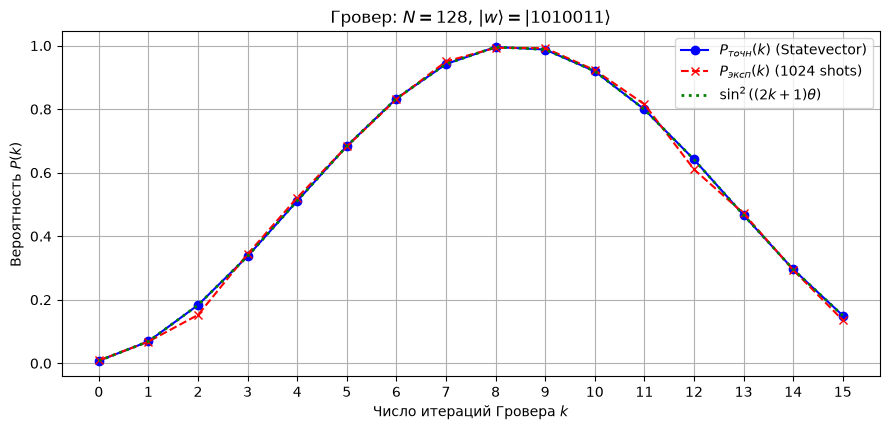

In [12]:
print("=== ЗАДАНИЕ 5.1: P(k) для N=128, |w>=|1010011> ===")

n5, marked5 = 7, "1010011"
N5 = 2 ** n5
theta5 = asin(1 / sqrt(N5))
oracle5, diffuser5 = build_oracle(n5, marked5), build_diffuser(n5)
print(f"N={N5}, |w>={marked5} ({int(marked5, 2)}), theta={theta5:.6f} рад\n")

K5 = list(range(16))
P_exact5 = [prob_marked(n5, oracle5, diffuser5, [marked5], k) for k in K5]
P_exp5 = [run_P(n5, oracle5, diffuser5, marked5, k, 1024, 21 * 100 + k) for k in K5]
P_theory5 = [sin((2 * k + 1) * theta5) ** 2 for k in K5]

hdr = f"{'k':>2} | {'P точное':>10} | {'P экспер.':>10} | {'sin²((2k+1)θ)':>14}"
print(hdr)
print("-" * len(hdr))
for k in K5:
    print(f"{k:>2} | {P_exact5[k]:>10.6f} | {P_exp5[k]:>10.6f} | {P_theory5[k]:>14.6f}")

plt.figure(figsize=(9, 4.4))
plt.plot(K5, P_exact5, 'b-o', label='$P_{точн}(k)$ (Statevector)')
plt.plot(K5, P_exp5, 'r--x', label='$P_{эксп}(k)$ (1024 shots)')
plt.plot(K5, P_theory5, 'g:', linewidth=2, label=r'$\sin^2((2k+1)\theta)$')
plt.xlabel('Число итераций Гровера $k$')
plt.ylabel('Вероятность $P(k)$')
plt.title('Гровер: $N=128$, $|w\\rangle=|1010011\\rangle$')
plt.xticks(K5)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

=== ЗАДАНИЕ 5.2: теоретический и экспериментальный оптимум ===
argmax точной P(k)          : 8  (P = 0.995620)
round(π/4·√N)               : 9  (P = 0.987779)
floor(π/4·√N)               : 8  (P = 0.995620)
argmax экспериментальной P(k): 8  (P = 0.993164)

P(8) = 0.995620, P(9) = 0.987779, ΔP = 0.007841
σ разности при 1024 shots: sqrt((p8(1-p8)+p9(1-p9))/1024) = 0.004006; ΔP/σ = 1.96
  shots для надёжности 95%: (z·sqrt(p8(1-p8)+p9(1-p9))/ΔP)² = 1027
  shots для надёжности 99.7%: (z·sqrt(p8(1-p8)+p9(1-p9))/ΔP)² = 2405

=== ЗАДАНИЕ 5.3: устойчивость оценки оптимума (20 запусков) ===


 shots | уникальный max при k=8 | доля ничьих
---------------------------------------------
    16 |                   0.10 |        0.90
    64 |                   0.50 |        0.50
   256 |                   0.90 |        0.10
  1024 |                   1.00 |        0.00


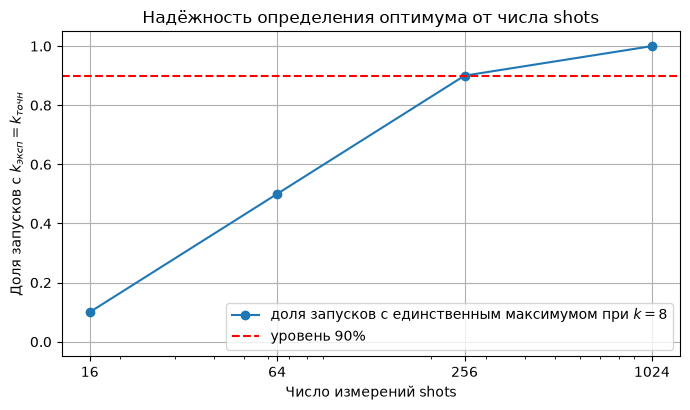

Минимальное число shots с долей ≥ 90%: 256


In [13]:
print("=== ЗАДАНИЕ 5.2: теоретический и экспериментальный оптимум ===")

k_exact5 = int(np.argmax(P_exact5))
k_round5 = round(pi / 4 * sqrt(N5))
k_floor5 = floor(pi / 4 * sqrt(N5))
k_exp5 = int(np.argmax(P_exp5))
print(f"argmax точной P(k)          : {k_exact5}  (P = {P_exact5[k_exact5]:.6f})")
print(f"round(π/4·√N)               : {k_round5}  (P = {P_exact5[k_round5]:.6f})")
print(f"floor(π/4·√N)               : {k_floor5}  (P = {P_exact5[k_floor5]:.6f})")
print(f"argmax экспериментальной P(k): {k_exp5}  (P = {P_exp5[k_exp5]:.6f})")

p8, p9 = P_exact5[8], P_exact5[9]
dP = p8 - p9
var_sum = p8 * (1 - p8) + p9 * (1 - p9)
sigma_diff = sqrt(var_sum / 1024)
print(f"\nP(8) = {p8:.6f}, P(9) = {p9:.6f}, ΔP = {dP:.6f}")
print(f"σ разности при 1024 shots: sqrt((p8(1-p8)+p9(1-p9))/1024) = {sigma_diff:.6f}; ΔP/σ = {dP / sigma_diff:.2f}")
for z, label in [(1.96, '95%'), (3.0, '99.7%')]:
    need = (z * sqrt(var_sum) / dP) ** 2
    print(f"  shots для надёжности {label}: (z·sqrt(p8(1-p8)+p9(1-p9))/ΔP)² = {need:.0f}")

print("\n=== ЗАДАНИЕ 5.3: устойчивость оценки оптимума (20 запусков) ===")
SHOTS_GRID = [16, 64, 256, 1024]
fractions = []
tie_fractions = []
for shots in SHOTS_GRID:
    good = 0
    ties = 0
    for seed in range(20):
        pk = [run_P(n5, oracle5, diffuser5, marked5, k, shots, seed * 100 + k) for k in K5]
        best = max(pk)
        winners = [k for k in K5 if pk[k] == best]
        if len(winners) > 1:
            ties += 1
        if winners == [k_exact5]:
            good += 1
    fractions.append(good / 20)
    tie_fractions.append(ties / 20)

hdr = f"{'shots':>6} | {'уникальный max при k=8':>22} | {'доля ничьих':>11}"
print(hdr)
print("-" * len(hdr))
for shots, f, t in zip(SHOTS_GRID, fractions, tie_fractions):
    print(f"{shots:>6} | {f:>22.2f} | {t:>11.2f}")

plt.figure(figsize=(7, 4.2))
plt.plot(SHOTS_GRID, fractions, 'o-', label='доля запусков с единственным максимумом при $k=8$')
plt.axhline(0.9, color='red', linestyle='--', label='уровень 90%')
plt.xscale('log')
plt.xlabel('Число измерений shots')
plt.ylabel('Доля запусков с $k_{эксп} = k_{точн}$')
plt.title('Надёжность определения оптимума от числа shots')
plt.xticks(SHOTS_GRID, [str(s) for s in SHOTS_GRID])
plt.ylim(-0.05, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

ok_shots = [s for s, f in zip(SHOTS_GRID, fractions) if f >= 0.9]
print(f"Минимальное число shots с долей ≥ 90%: {min(ok_shots) if ok_shots else 'не достигнуто'}")

### Ответы на вопросы задания 5.2
- **Теоретически оптимальное $k$.** Округление $k_{\text{round}} = \mathrm{round}(\pi\sqrt{128}/4) = 9$ — лишь грубая оценка: истинный максимум $P(k) = \sin^2((2k+1)\theta)$ на целых $k$ достигается при $k = 8$ ($P(8) = 0.995620$), тогда как $P(9) = 0.987779$. Совпадение $k_{\text{floor}} = 8$ с истинным argmax здесь точное, но в общем случае $\lfloor \pi\sqrt{N}/4 \rfloor$ тоже не гарантирует максимума — его нужно проверять по формуле.
- **Экспериментальный оптимум.** По 1024 shots максимум также попадает в $k = 8$ ($P_{эксп} = 0.993164$ против 0.992188 при $k = 9$). Разница $P(8) - P(9) = 0.007841$ сравнима со статистической погрешностью: при 1024 shots $\sigma$ разности двух долей равна 0.004006, то есть разрыв составляет всего $\approx 1.96\sigma$ — выборка вполне может «переставить» соседние $k$. Чтобы различие стало надёжным, нужно $\approx 1027$ shots для уровня 95% и $\approx 2405$ shots для 99.7%.
- **Устойчивость оценки оптимума.** В 20 независимых запусках доля случаев, когда выборка дала *единственный* максимум именно при $k = 8$, составила 0.10 (16 shots), 0.50 (64), 0.90 (256) и 1.00 (1024); доля запусков с ничьей между соседними $k$ — 0.90, 0.50, 0.10 и 0.00 соответственно. При 16 shots значения $P(7)=0.942$, $P(8)=0.996$ и $P(9)=0.988$ дают по 15–16 попаданий из 16, поэтому максимум почти всегда не единственный; при 64 shots $k=7$ уже надёжно отделён (в среднем 60 попаданий против 64), и конкурируют только $k=8$ и $k=9$; при 1024 shots разрыв $\Delta P = 0.0078$ составляет $\approx 2\sigma$, поэтому максимум единственный почти во всех запусках. Формально по этим 20 запускам порог 90% достигается при 256 shots, однако 20 запусков — малая выборка (стандартная ошибка доли $\approx 0.07$), а аналитическая оценка для 95% надёжного различения $k=8$ и $k=9$ даёт $\approx 1027$ shots; поэтому практическим минимумом следует считать 1024 shots.

**Вывод по Заданию 5:**
- Точная и экспериментальная кривые $P(k)$ совпадают с теоретической $\sin^2((2k+1)\theta)$: вероятность растёт от $1/128 = 0.007812$ при $k=0$ до 0.995620 при $k=8$ и затем падает из-за «перекручивания» вектора состояния.
- Оптимум: $k_{\text{точн}} = 8$, $k_{\text{эксп}} = 8$; округление даёт 9, что подтверждает необходимость прямой проверки формулы. Разрыв $P(8) - P(9) = 0.007841$ при 1024 shots статистически значим лишь на уровне $\approx 2\sigma$.
- Доля запусков с единственным максимумом при $k=8$ растёт с числом shots: 0.10, 0.50, 0.90 и 1.00 для 16, 64, 256 и 1024 shots. Формально порог 90% достигается при 256 shots, но из-за малого числа запусков и аналитической оценки $\approx 1027$ shots для 95% надёжности практический минимум — 1024 shots.

---
## Задание 6. Алгоритм Гровера при наличии $M$ решений ($N = 2^6 = 64$)

При $M$ отмеченных состояниях начальный вектор образует с подпространством неотмеченных состояний угол $\theta_M = \arcsin\sqrt{M/N}$, а вероятность найти одно из отмеченных состояний после $k$ итераций:
$$P(k) = \sin^2\big((2k+1)\theta_M\big), \qquad k_{\text{opt}}(M) = \left\lfloor\frac{\pi}{4}\sqrt{\frac{N}{M}}\right\rfloor.$$
Оракул для набора $W$ строится как произведение фазовых инверсий $O_W = \prod_{w \in W} O_w$ (они коммутируют и действуют в разных базисных состояниях). Отмеченные состояния выбираются случайно с фиксированным `seed` и без повторов. Период колебаний по $k$ равен $\pi/(2\theta_M)$, поэтому при неудачном целом $k$ первый локальный максимум может оказаться ниже одного из последующих.

=== ЗАДАНИЕ 6.1–6.2: P(k) при M решениях, N=2^6=64 ===
 M | отмеченные индексы                 | k теор | k 1-й макс |        P | global | P(global)
--------------------------------------------------------------------------------------------------------


 1 | [52]                               |      6 |          6 | 0.996586 |      6 |  0.996586


 2 | [26, 37]                           |      4 |          4 | 0.999182 |      4 |  0.999182


 3 | [20, 27, 51]                       |      3 |          3 | 0.998139 |      3 |  0.998139


 4 | [9, 13, 17, 30]                    |      3 |          3 | 0.961319 |     15 |  0.999564


 8 | [9, 12, 20, 26, 33, 36, 42, 47]    |      2 |          2 | 0.945312 |      6 |  0.999786


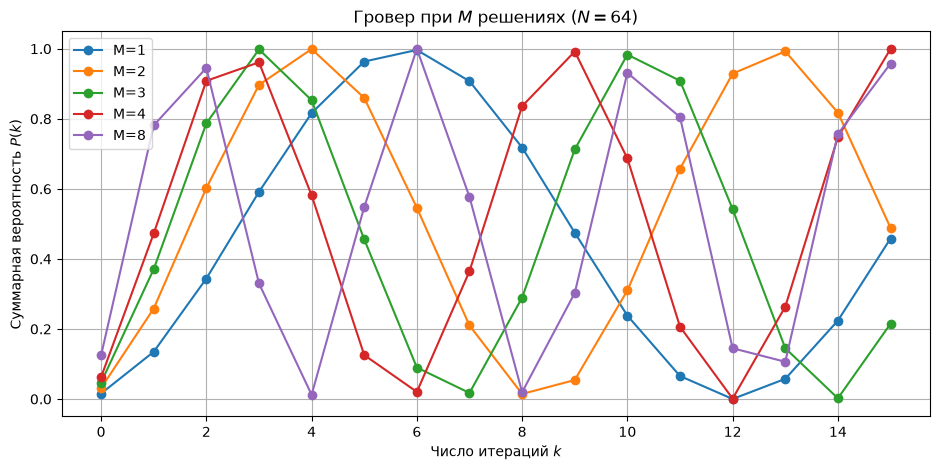

In [14]:
print("=== ЗАДАНИЕ 6.1–6.2: P(k) при M решениях, N=2^6=64 ===")
n6, N6 = 6, 64
np.random.seed(42)
diffuser6 = build_diffuser(n6)

M_LIST = [1, 2, 3, 4, 8]
res6 = {}
plt.figure(figsize=(9.5, 4.8))

print(f"{'M':>2} | {'отмеченные индексы':<34} | {'k теор':>6} | {'k 1-й макс':>10} | {'P':>8} | {'global':>6} | {'P(global)':>9}")
print("-" * 104)
for M in M_LIST:
    idx = sorted(int(x) for x in np.random.choice(list(range(N6)), M, replace=False))
    strings = [format(x, f'0{n6}b') for x in idx]
    oracle = QuantumCircuit(n6)
    for s in strings:
        oracle.compose(build_oracle(n6, s), inplace=True)
    P = [prob_marked(n6, oracle, diffuser6, strings, k) for k in range(16)]
    k_first = next(k for k in range(1, 15) if P[k] > P[k - 1] and P[k] >= P[k + 1])
    k_theor = floor(pi / 4 * sqrt(N6 / M))
    k_global = int(np.argmax(P))
    res6[M] = dict(idx=idx, strings=strings, P=P, k_first=k_first,
                   k_theor=k_theor, k_global=k_global)
    print(f"{M:>2} | {str(idx):<34} | {k_theor:>6} | {k_first:>10} | {P[k_first]:>8.6f} | "
          f"{k_global:>6} | {P[k_global]:>9.6f}")
    plt.plot(range(16), P, marker='o', label=f'M={M}')

plt.xlabel('Число итераций $k$')
plt.ylabel('Суммарная вероятность $P(k)$')
plt.title('Гровер при $M$ решениях ($N=64$)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
print("=== ЗАДАНИЕ 6.3: глобальный максимум против первого локального ===")
hdr = f"{'M':>2} | {'k 1-го макс':>11} | {'P(1-го)':>8} | {'argmax':>6} | {'P(argmax)':>9} | {'период π/(2θ_M)':>16}"
print(hdr)
print("-" * len(hdr))
for M in M_LIST:
    r = res6[M]
    thetaM = asin(sqrt(M / N6))
    period = pi / (2 * thetaM)
    print(f"{M:>2} | {r['k_first']:>11} | {r['P'][r['k_first']]:>8.6f} | {r['k_global']:>6} | "
          f"{r['P'][r['k_global']]:>9.6f} | {period:>16.3f}")

print("\nПоложения пиков sin²((2k+1)θ_M) (нецелые значения k, ближайшие целые выделены):")
for M in (4, 8):
    thetaM = asin(sqrt(M / N6))
    peaks = [((pi / 2 + m * pi) / thetaM - 1) / 2 for m in range(4)]
    print(f"  M={M}: θ_M={thetaM:.6f}, период={pi / (2 * thetaM):.3f}, пики k = " +
          ", ".join(f"{p:.2f}" for p in peaks))

print("\n=== ЗАДАНИЕ 6.4: M = N/2 = 32 и M = 3N/4 = 48 ===")
for M in (32, 48):
    idx = sorted(int(x) for x in np.random.choice(list(range(N6)), M, replace=False))
    strings = [format(x, f'0{n6}b') for x in idx]
    oracle = QuantumCircuit(n6)
    for s in strings:
        oracle.compose(build_oracle(n6, s), inplace=True)
    P = [prob_marked(n6, oracle, diffuser6, strings, k) for k in range(7)]
    print(f"\nM={M} ({M}/{N6}N): θ_M = arcsin(√(M/N)) = {asin(sqrt(M / N6)):.6f} рад")
    print(f"  {'k':>2} | {'P(k)':>8}")
    for k, p in enumerate(P):
        print(f"  {k:>2} | {p:>8.6f}")

=== ЗАДАНИЕ 6.3: глобальный максимум против первого локального ===
 M | k 1-го макс |  P(1-го) | argmax | P(argmax) |  период π/(2θ_M)
-------------------------------------------------------------------
 1 |           6 | 0.996586 |      6 |  0.996586 |           12.533
 2 |           4 | 0.999182 |      4 |  0.999182 |            8.839
 3 |           3 | 0.998139 |      3 |  0.998139 |            7.198
 4 |           3 | 0.961319 |     15 |  0.999564 |            6.217
 8 |           2 | 0.945312 |      6 |  0.999786 |            4.347

Положения пиков sin²((2k+1)θ_M) (нецелые значения k, ближайшие целые выделены):
  M=4: θ_M=0.252680, период=6.217, пики k = 2.61, 8.82, 15.04, 21.26
  M=8: θ_M=0.361367, период=4.347, пики k = 1.67, 6.02, 10.37, 14.71

=== ЗАДАНИЕ 6.4: M = N/2 = 32 и M = 3N/4 = 48 ===



M=32 (32/64N): θ_M = arcsin(√(M/N)) = 0.785398 рад
   k |     P(k)
   0 | 0.500000
   1 | 0.500000
   2 | 0.500000
   3 | 0.500000
   4 | 0.500000
   5 | 0.500000
   6 | 0.500000



M=48 (48/64N): θ_M = arcsin(√(M/N)) = 1.047198 рад
   k |     P(k)
   0 | 0.750000
   1 | 0.000000
   2 | 0.750000
   3 | 0.750000
   4 | 0.000000
   5 | 0.750000
   6 | 0.750000


### Ответы на вопросы задания 6
- **Первый максимум и формула.** Для $M = 1,2,3,4,8$ первый локальный максимум $P(k)$ равен 6, 4, 3, 3, 2 и совпадает с $\lfloor \pi\sqrt{N/M}/4 \rfloor$; в этих точках $P$ равна 0.996586, 0.999182, 0.998139, 0.961319, 0.945312.
- **Случаи расхождения глобального и первого максимума.** При $M = 4$ глобальный максимум достигается при $k = 15$ ($P = 0.999564$) вместо $k = 3$ ($P = 0.961319$), при $M = 8$ — при $k = 6$ ($P = 0.999786$) вместо $k = 2$ ($P = 0.945312$). Причина: $P(k)$ периодична по $k$ с периодом $\pi/(2\theta_M)$; для $M=4$ пики лежат в точках $k \approx 2.6;\ 8.8;\ 15.0$, поэтому целое $k = 15$ оказывается ближе к истинному пику, чем $k = 3$; для $M=8$ пики $k \approx 1.7;\ 6.0$, и $k = 6$ почти точно попадает в максимум.
- **Правило выбора $k$.** Нужно брать *первый* пик (минимальное $k$): он требует минимум итераций и, следовательно, минимум вентилей и ошибок. Если из-за целочисленного округления вероятность первого пика заметно меньше 1, можно взять более поздний пик $k + \text{период}$ — но цена линейно растёт вместе с числом итераций и глубиной схемы, что при наличии шума обычно невыгодно.
- **$M = N/2$ и $M = 3N/4$.** При $M = 32$ ($\theta_M = \pi/4$) вероятность равна 0.5 при любом $k$ — амплификации нет, алгоритм бесполезен. При $M = 48$ ($\theta_M = \pi/3$) значения чередуются: 0.75 при $k = 0, 2, 3, 5, 6$ и 0 при $k = 1, 4$, то есть лучший результат достигается уже при $k = 0$ и итерации только вредят. Вывод: Гровер даёт выигрыш лишь при $M \ll N$ (фактически при $M < N/2$).

**Вывод по Заданию 6:**
- С ростом $M$ период осцилляций сокращается: первый максимум достигается при $k = 6, 4, 3, 3, 2$ для $M = 1, 2, 3, 4, 8$, что подтверждает закон $\sqrt{N/M}$.
- Глобальный максимум на отрезке $0\dots15$ не совпал с первым локальным при $M = 4$ ($k = 15$, $P = 0.999564$) и $M = 8$ ($k = 6$, $P = 0.999786$); причина — целочисленное округление положения периодических пиков.
- При $M = N/2 = 32$ вероятность постоянна и равна 0.5, при $M = 3N/4 = 48$ — чередуется 0.75/0; ускорение Гровера исчезает при $M \gtrsim N/2$.

---
## Задание 7 (вариант 21). Поиск состояния $|0101010\rangle$ при $N = 2^7 = 128$

Параметры варианта 21:
- $n = 7$, $N = 2^7 = 128$; отмеченное состояние $|w\rangle = |0101010\rangle$ ($42_{10}$);
- $\theta = \arcsin(1/\sqrt{128}) \approx 0.088504$ рад;
- $k_{\text{теор}} = \lfloor \pi\sqrt{128}/4 \rfloor = 8$; $P(k) = \sin^2((2k+1)\theta)$.

Оракул строится функцией `build_oracle` из задания 4 (не вручную). Дополнительно исследуются:
1. сводная таблица по группе вариантов 21–30 ($N = 2^7$) — зависимость оптимального $k$ от отмеченного состояния при $M = 1$;
2. влияние двухкубитного деполяризующего шума на высоту и положение максимума $P(k)$ для варианта 21 ($n = 7$) и для примера из задания — варианта 1 ($n = 5$, $|01010\rangle$).

=== ЗАДАНИЕ 7.1: вариант 21, N=2^7=128, |w>=|0101010> ===
N=128, |w>=0101010 (42), theta=0.088504 рад
k теор = floor(π/4·√N) = 8



 k |   P точное |  P экспер. |  sin²((2k+1)θ)
---------------------------------------------
 0 |   0.007812 |   0.011719 |       0.007812
 1 |   0.068855 |   0.074219 |       0.068855
 2 |   0.183370 |   0.182617 |       0.183370
 3 |   0.337154 |   0.338867 |       0.337154
 4 |   0.511136 |   0.520508 |       0.511136
 5 |   0.683735 |   0.688477 |       0.683735
 6 |   0.833548 |   0.835938 |       0.833548
 7 |   0.941993 |   0.942383 |       0.941993
 8 |   0.995620 |   0.993164 |       0.995620
 9 |   0.987779 |   0.992188 |       0.987779
10 |   0.919441 |   0.919922 |       0.919441
11 |   0.799084 |   0.786133 |       0.799084
12 |   0.641632 |   0.605469 |       0.641632
13 |   0.466616 |   0.457031 |       0.466616
14 |   0.295739 |   0.313477 |       0.295739
15 |   0.150196 |   0.148438 |       0.150196


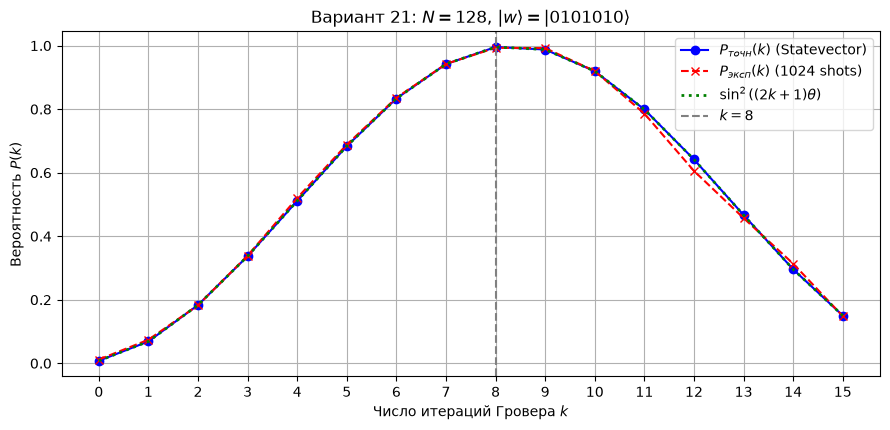

In [16]:
print("=== ЗАДАНИЕ 7.1: вариант 21, N=2^7=128, |w>=|0101010> ===")
n7, marked7 = 7, "0101010"
N7 = 2 ** n7
theta7 = asin(1 / sqrt(N7))
oracle7, diffuser7 = build_oracle(n7, marked7), build_diffuser(n7)
print(f"N={N7}, |w>={marked7} ({int(marked7, 2)}), theta={theta7:.6f} рад")
print(f"k теор = floor(π/4·√N) = {floor(pi / 4 * sqrt(N7))}\n")

K7 = list(range(16))
P_exact7 = [prob_marked(n7, oracle7, diffuser7, [marked7], k) for k in K7]
P_exp7 = [run_P(n7, oracle7, diffuser7, marked7, k, 1024, 21 * 100 + k) for k in K7]
P_theory7 = [sin((2 * k + 1) * theta7) ** 2 for k in K7]

hdr = f"{'k':>2} | {'P точное':>10} | {'P экспер.':>10} | {'sin²((2k+1)θ)':>14}"
print(hdr)
print("-" * len(hdr))
for k in K7:
    print(f"{k:>2} | {P_exact7[k]:>10.6f} | {P_exp7[k]:>10.6f} | {P_theory7[k]:>14.6f}")

plt.figure(figsize=(9, 4.4))
plt.plot(K7, P_exact7, 'b-o', label='$P_{точн}(k)$ (Statevector)')
plt.plot(K7, P_exp7, 'r--x', label='$P_{эксп}(k)$ (1024 shots)')
plt.plot(K7, P_theory7, 'g:', linewidth=2, label=r'$\sin^2((2k+1)\theta)$')
plt.axvline(8, color='gray', linestyle='--', label='$k=8$')
plt.xlabel('Число итераций Гровера $k$')
plt.ylabel('Вероятность $P(k)$')
plt.title('Вариант 21: $N=128$, $|w\\rangle=|0101010\\rangle$')
plt.xticks(K7)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
print("=== ЗАДАНИЕ 7.2: сводная таблица по варианту 21 ===")
k_th7 = floor(pi / 4 * sqrt(N7))
k_ex7 = next(k for k in range(1, 15) if P_exact7[k] > P_exact7[k - 1] and P_exact7[k] >= P_exact7[k + 1])
k_exp7 = int(np.argmax(P_exp7))
hdr = f"{'вариант':>7} | {'N':>4} | {'|w>':>8} | {'k теор':>6} | {'k точн':>6} | {'k эксп':>6} | {'max P точн':>10}"
print(hdr)
print("-" * len(hdr))
print(f"{21:>7} | {N7:>4} | {marked7:>8} | {k_th7:>6} | {k_ex7:>6} | {k_exp7:>6} | {max(P_exact7):>10.6f}")

print("\n=== ЗАДАНИЕ 7.3: группа N=2^7 (варианты 21–30) ===")
GROUP = ["0101010", "1010101", "1100110", "0011001", "1111000",
         "0000111", "1001011", "0110100", "1011010", "0100101"]
hdr = f"{'вариант':>7} | {'|w>':>8} | {'k точн':>6} | {'k эксп':>6} | {'P эксп(k эксп)':>14}"
print(hdr)
print("-" * len(hdr))
k_exact_group, k_exp_group = [], []
for i, state in enumerate(GROUP):
    o = build_oracle(n7, state)
    d = build_diffuser(n7)
    Pex = [prob_marked(n7, o, d, [state], k) for k in K7]
    Pexp = [run_P(n7, o, d, state, k, 1024, (21 + i) * 100 + k) for k in K7]
    kex = next(k for k in range(1, 15) if Pex[k] > Pex[k - 1] and Pex[k] >= Pex[k + 1])
    kep = int(np.argmax(Pexp))
    k_exact_group.append(kex)
    k_exp_group.append(kep)
    print(f"{21 + i:>7} | {state:>8} | {kex:>6} | {kep:>6} | {Pexp[kep]:>14.6f}")

print(f"\nВсе k точн равны 8: {all(k == 8 for k in k_exact_group)}; "
      f"k эксп принимает значения {sorted(set(k_exp_group))} "
      f"(разброс — только статистика 1024 shots).")

=== ЗАДАНИЕ 7.2: сводная таблица по варианту 21 ===
вариант |    N |      |w> | k теор | k точн | k эксп | max P точн
-----------------------------------------------------------------
     21 |  128 |  0101010 |      8 |      8 |      8 |   0.995620

=== ЗАДАНИЕ 7.3: группа N=2^7 (варианты 21–30) ===
вариант |      |w> | k точн | k эксп | P эксп(k эксп)
-----------------------------------------------------


     21 |  0101010 |      8 |      8 |       0.993164


     22 |  1010101 |      8 |      9 |       0.993164


     23 |  1100110 |      8 |      8 |       0.992188


     24 |  0011001 |      8 |      8 |       0.996094


     25 |  1111000 |      8 |      8 |       0.995117


     26 |  0000111 |      8 |      8 |       0.995117


     27 |  1001011 |      8 |      8 |       0.996094


     28 |  0110100 |      8 |      8 |       0.999023


     29 |  1011010 |      8 |      8 |       0.998047


     30 |  0100101 |      8 |      8 |       0.995117

Все k точн равны 8: True; k эксп принимает значения [8, 9] (разброс — только статистика 1024 shots).


=== ЗАДАНИЕ 7.4: влияние двухкубитного шума ===
Шум: 1q деполяризующий p1=0.001 на ['rz','sx','x'], 2q деполяризующий p2 на ['cx']

вариант |    p2 | CX за итерацию | глубина k=15 | argmax k |  max P(k)
----------------------------------------------------------------------


     21 | 0.005 |            244 |         4071 |        2 |    0.0176


     21 |  0.02 |            244 |         4071 |       15 |    0.0127


      1 | 0.005 |             72 |         2344 |        3 |    0.3076


      1 |  0.02 |             72 |         2344 |        1 |    0.0957

Теоретическая оценка выживания без ошибок: (1 - 15/16·p2)^(CX за итерацию)
  n=7, p2=0.005: p_eff=0.00469, (1-p_eff)^244 = 0.3178
  n=7, p2=0.02: p_eff=0.01875, (1-p_eff)^244 = 0.0099
  n=5, p2=0.005: p_eff=0.00469, (1-p_eff)^72 = 0.7130
  n=5, p2=0.02: p_eff=0.01875, (1-p_eff)^72 = 0.2559


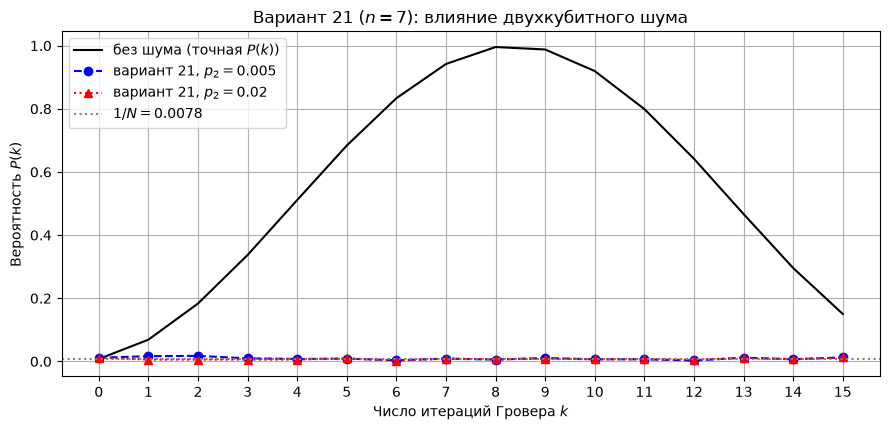

In [18]:
print("=== ЗАДАНИЕ 7.4: влияние двухкубитного шума ===")
print("Шум: 1q деполяризующий p1=0.001 на ['rz','sx','x'], 2q деполяризующий p2 на ['cx']\n")

def noisy_sweep(n, marked, p2, shots=1024, seed=7):
    oracle, diffuser = build_oracle(n, marked), build_diffuser(n)
    tqcs = [transpile(grover_circuit(n, oracle, diffuser, k), basis_gates=['rz', 'sx', 'x', 'cx'],
                      optimization_level=1) for k in K7]
    cx_per_iter = tqcs[1].count_ops().get('cx', 0) - tqcs[0].count_ops().get('cx', 0)
    nm = build_noise_model(p2)
    P = []
    for k in K7:
        counts = sim.run(tqcs[k], shots=shots, noise_model=nm,
                         seed_simulator=seed * 100 + k).result().get_counts()
        P.append(counts.get(marked, 0) / shots)
    return P, cx_per_iter, tqcs[-1].depth()

hdr = f"{'вариант':>7} | {'p2':>5} | {'CX за итерацию':>14} | {'глубина k=15':>12} | {'argmax k':>8} | {'max P(k)':>9}"
print(hdr)
print("-" * len(hdr))
noise_results = {}
for variant, nv, state in [(21, 7, "0101010"), (1, 5, "01010")]:
    for p2 in (0.005, 0.02):
        P, cx_iter, depth_last = noisy_sweep(nv, state, p2)
        noise_results[(variant, p2)] = (P, cx_iter, depth_last)
        print(f"{variant:>7} | {p2:>5} | {cx_iter:>14} | {depth_last:>12} | "
              f"{int(np.argmax(P)):>8} | {max(P):>9.4f}")

print("\nТеоретическая оценка выживания без ошибок: (1 - 15/16·p2)^(CX за итерацию)")
for nv, cx_iter in [(7, noise_results[(21, 0.005)][1]), (5, noise_results[(1, 0.005)][1])]:
    for p2 in (0.005, 0.02):
        surv = (1 - 15 / 16 * p2) ** cx_iter
        print(f"  n={nv}, p2={p2}: p_eff={15 / 16 * p2:.5f}, (1-p_eff)^{cx_iter} = {surv:.4f}")

plt.figure(figsize=(9, 4.4))
plt.plot(K7, P_exact7, 'k-', label='без шума (точная $P(k)$)')
for p2, style in [(0.005, 'b--o'), (0.02, 'r:^')]:
    P = noise_results[(21, p2)][0]
    plt.plot(K7, P, style, label=f'вариант 21, $p_2={p2}$')
plt.axhline(1 / N7, color='gray', linestyle=':', label='$1/N = 0.0078$')
plt.xlabel('Число итераций Гровера $k$')
plt.ylabel('Вероятность $P(k)$')
plt.title('Вариант 21 ($n=7$): влияние двухкубитного шума')
plt.xticks(K7)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Ответы на вопросы задания 7
1. **Зависимость $k_{\text{opt}}$ от отмеченного состояния при $M = 1$.** Нет: кривая $P(k) = \sin^2((2k+1)\theta)$ зависит только от $N$ и $M$, а не от конкретного $|w\rangle$, поэтому для всех десяти состояний группы точный первый максимум одинаков и равен $k = 8$ (все $k_{\text{точн}}$ в таблице равны 8). Разброс экспериментальных оценок $k_{\text{эксп}} \in \{8, 9\}$ внутри группы — чисто статистический: $P(8) - P(9) = 0.0078$, и при 1024 shots выборка иногда отдаёт максимум соседнему $k$.
2. **Влияние шума.** Уже при $p_2 = 0.005$ максимум $P(k)$ для варианта 21 падает с 0.9956 до 0.0176 (примерно $2.3$ уровня $1/N = 0.0078$), а при $p_2 = 0.02$ — до 0.0127 (примерно $1.6$ уровня $1/N$). Распределение практически выходит на шумовой уровень, поэтому положение argmax ($k = 2$ при $p_2 = 0.005$ и $k = 15$ при $p_2 = 0.02$) теряет физический смысл — это флуктуация шумового фона, а не усиление Гровера. Причина — экспоненциальный рост вероятности ошибки с числом `CX`: одна итерация для $n = 7$ после транспиляции содержит 244 `CX` (глубина схемы при $k=15$ достигает 4071 слоя), поэтому вероятность пройти первую же итерацию без ошибки $\approx (1 - \tfrac{15}{16}p_2)^{244}$ составляет лишь 0.3178 при $p_2 = 0.005$ и 0.0099 при $p_2 = 0.02$. Для варианта 1 ($n = 5$, 72 `CX` за итерацию) максимум сохраняется на уровне 0.3076 при $p_2 = 0.005$ и 0.0957 при $p_2 = 0.02$ — меньшее число `CX` и меньшая глубина дают заметно большую устойчивость. Именно поэтому глубина схемы критична: выигрыш Гровера $\sqrt{N}$ достигается только при достаточно малой ошибке на вентиль, иначе нужны коды коррекции ошибок.

**Вывод по Заданию 7:**
- Для варианта 21 ($N = 128$, $|w\rangle = |0101010\rangle$) точный и экспериментальный оптимум равны $k = 8$, максимальная точная вероятность $P(8) = 0.995620$ — в 127 раз выше классического случайного выбора $1/N = 0.007812$.
- Для всей группы вариантов 21–30 точный первый максимум одинаков ($k = 8$), то есть при $M = 1$ оптимальное число итераций не зависит от отмеченного состояния; экспериментальные значения $k_{\text{эксп}} \in \{8, 9\}$ отличаются только из-за статистики измерений.
- Шум разрушает выигрыш: при $p_2 = 0.005$ максимум $P(k)$ для $n = 7$ падает до 0.0176, при $p_2 = 0.02$ — до 0.0127 (уровень $1/N$), а положение argmax становится случайным ($k = 2$ и $k = 15$); для варианта 1 ($n = 5$, 72 `CX` за итерацию) максимум сохраняется на уровне 0.3076 и 0.0957 соответственно.

---
## Общий вывод

В работе реализованы и проверены все элементы лабораторной работы №5 для варианта 21.

1. **Сумматоры.** Прямой 5-кубитный полный сумматор (3 `CX`, 3 `CCX`, глубина 5) и сумматор из двух полусумматоров и ИЛИ (8 кубитов, 4 `CX`, 3 `CCX`, 5 `X`, глубина 8) дают правильный результат на всех 8 наборах входов; при $A=1$, $B=0$, $X=1$ получены $S=0$, $C=1$. Прямая реализация экономичнее по всем метрикам. Ripple-carry сумматор требует $4n+1$ кубитов, $3n$ `CX` и $3n$ `CCX`; глубина растёт линейно — 8, 11 и 14 для $n = 2, 3, 4$, а все 336 пар слагаемых (16 + 64 + 256) сложены верно.
2. **Булева функция варианта 21** $F = (A \land B) \oplus (C \lor D)$ реализована из модульных подсхем в двух версиях: базовая — 9 кубитов, 10 `CX`, 4 `CCX`, глубина 9; оптимизированная — 7 кубитов, 6 `CX`, 4 `CCX`, глубина 7. Обе версии верны на всех 16 входах, все анциллы возвращаются в $|0\rangle$ благодаря `inverse()`.
3. **Шум.** После транспиляции базовая схема содержит 34 `CX`, оптимизированная — 30. При $p_2 = 0.02$ доля правильных ответов падает до 0.8735 и 0.8921 соответственно; оптимизированная версия устойчивее, а среднее отношение логарифмов долей (1.1047) согласуется с отношением числа `CX` (1.1333).
4. **Оракул и диффузор** проверены матрично для $n = 2,3,4,5$ (60 оракулов и 1360 базисных состояний, отклонение $\le 3.2\cdot10^{-15}$); диффузор совпадает с $-(2|s\rangle\langle s| - I)$, а для $n=3$ вероятности после $k=1,2$ итераций равны 0.781250 и 0.945312 — точно по формуле $\sin^2((2k+1)\theta)$.
5. **Поиск при $N = 128$.** Максимум $P(8) = 0.995620$ (против $P(9) = 0.987779$), то есть истинный оптимум $k = 8$, тогда как округление $\mathrm{round}(\pi\sqrt{N}/4)$ даёт 9. Надёжное различение соседних $k$ требует $\approx 1027$ shots (95%); в 20 запусках доля единственного максимума при $k=8$ составила 0.10, 0.50, 0.90 и 1.00 для 16, 64, 256 и 1024 shots — формально порог 90% достигается при 256 shots, но практический минимум с учётом аналитической оценки — 1024 shots.
6. **Несколько решений ($N = 64$).** Первые максимумы равны 6, 4, 3, 3, 2 для $M = 1,2,3,4,8$ и совпадают с $\lfloor\pi\sqrt{N/M}/4\rfloor$; при $M=4$ и $M=8$ глобальный максимум смещается к $k=15$ ($P=0.999564$) и $k=6$ ($P=0.999786$) из-за периодичности $P(k)$. При $M = 32$ вероятность постоянна (0.5), при $M = 48$ чередуется 0.75/0 — ускорение существует только при $M \ll N$.
7. **Вариант 21 ($N = 128$, $|0101010\rangle$).** Оптимум $k = 8$, $P = 0.995620$; для всех состояний группы 21–30 точный оптимум одинаков, а разброс $k_{\text{эксп}} \in \{8,9\}$ статистический. Шум с $p_2 = 0.005$ уже снижает максимум до 0.0176 (244 `CX` на итерацию), а при $p_2 = 0.02$ — до 0.0127, то есть преимущество Гровера практически исчезает; для варианта 1 ($n=5$) те же уровни шума дают 0.3076 и 0.0957. Глубина схемы и коррекция ошибок критичны для практической реализации.